## Simulations showing the robustness of different apical release fractions and wash recovery fractions

## 0. General 

### 0.1. load libraries

In [1]:
import os, json, bisect, math, random, dendropy
from Bio import SeqIO
from Bio.Seq import Seq
import pandas as pd, numpy as np, statistics as st, scipy as sp

from matplotlib.lines import Line2D
import matplotlib.patheffects as path_effects
from matplotlib import rcParams
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.stats import binom

from scipy.optimize import minimize
import seaborn as sns

from matplotlib.colors import ListedColormap, BoundaryNorm



In [2]:
#plot settings
sns.set_theme(style="white", font="Arial")
# Set global font to Arial
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']

rcParams['font.size'] = 12
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True

### 0.2. General variables

In [3]:
detection_limit = 0.01

In [4]:
passages = [0,10,20,30,40,50,60,70,80,90,100]

### 0.3 Functions

In [5]:
def neg_log_likelihood(p, observations, trials):
        total_log_likelihood = 0
        for i, x in enumerate(observations):
            n = trials[i]
            total_log_likelihood += binom.logpmf(x, n, p)
        return -total_log_likelihood

def estimate_binomial_mean(count, depth):
    # calculate maximum likelihood estimate using Nelder-Mead for noisy measurements
    x0 = st.mean([count[i]/x for i, x in enumerate(depth)]) #initial guess 
    result = minimize(neg_log_likelihood, x0=x0, args=(count, depth), bounds=[(0, 1)], method="Nelder-Mead")
    if not result.success:
        raise Exception(f'optimizer was not successfull')
    p_mle = result.x[0]
    return p_mle


def load_simulation_results(simulation_file, lim=None):
    simulations = pd.read_csv(simulation_file)
    #only working with the first 100 simulation here for now
    if lim is not None:
        simulations = simulations[simulations["simulation"]<lim]
    simulations = simulations.melt(id_vars=["simulation", "passage", "replicate", "depth"], var_name="position", value_name="count")

    for c in simulations.columns:
        simulations[c] = simulations[c].astype(int)

    simulations = simulations.reset_index(drop=True)
    simulations['frequency'] = simulations['count'] /simulations['depth']

    simulations = simulations.pivot(index=["simulation", "position", "passage"],columns="replicate",
                    values=["depth", "count", "frequency"])
    simulations.columns = [f"{c[0]} {c[1]}" for c in simulations.columns]

    #remove observation where both freq 1 and freq 2 are below the detection limit
    #'true frequency' will then be under the detection limit anyway so there is no point of estimating the true frequency
    simulations = simulations[(simulations["frequency 1"]>=detection_limit)|(simulations["frequency 2"]>=detection_limit)]

    #using maximum likelihood estimation of the binomial proportions estimate the nucleotide, codon, and amino acid frequency
    for i, row in simulations.iterrows():
        counts = row[[c for c in simulations.columns if "count" in c]]
        depths = row[[c for c in simulations.columns if "depth" in c]]
        simulations.loc[i, "frequency"] = estimate_binomial_mean([int(nc) for nc in counts], [int(nd) for nd in depths])

    #drop techical replicate columns  > save space
    simulations = simulations.drop(columns=[c for c in simulations.columns if c !="frequency"])

        
    #remove all observations that have an estimated true frequecy below the detection limit 
    simulations = simulations[simulations["frequency"]>=detection_limit]

    #pivot to frequencies 
    simulations = simulations.reset_index().pivot(index=["simulation", "position"], columns=["passage"]).fillna(0)
    simulations.columns = simulations.columns.droplevel(0)
    return simulations

## 1. Run sims

In [6]:
sim_dir = "../results/simulations/apical_wash_sensitivity_analysis"
if not os.path.isdir(sim_dir):
    os.makedirs(sim_dir)
processed_sim_dir = os.path.join(sim_dir, "processed_output")
if not os.path.isdir(processed_sim_dir):
    os.makedirs(processed_sim_dir)

In [7]:
param_dict = {"--n-sims": 10,
              "--passages": 100,
              "--input-virions":1000,
              "--successful-infection-frac": 0.9,
            #   "--wash-recovery-frac":0.5,
            #   "--apical-release-fraction":0.5,
              "-mu":0.000003, #3e-6
              "--within-host-basic-reproduction-number":5,
              "--genome-length": str(2281), #longest gene segment
              
              }

threads = 10

In [8]:
apical_release_fractions = [0.1, 0.25, 0.5, 0.75, 0.8, 0.9]

redo = False
apical_simulations = []
for apical_release_frac in apical_release_fractions:
    file_name = f"simulation_arf_{apical_release_frac}_wrf_{0.5}.csv"
    
    simulation_file = os.path.join(sim_dir, file_name)
    processed_sim_file = os.path.join(processed_sim_dir, file_name)
    
    if not os.path.isfile(processed_sim_file) or redo:
        if not os.path.isfile(simulation_file) or redo:
            
            #cmd = ["conda", "run", "-n", "ltee-sim", "python", "../scripts/simulations.py", '-t', str(threads), '-o', simulation_file, "--genome-length", str(gl), '-v']
            cmd = ["python", "./scripts/simulations.py", '-t', str(threads), '-o', simulation_file.replace("../../", "../"),   "--wash-recovery-frac", str(0.5),
                   "--apical-release-fraction", str(apical_release_frac), '-v']
            for p, v in param_dict.items():
                cmd.extend([p, str(v)])
            print (" ".join(cmd))
                
            continue
        else:
            sims = load_simulation_results(simulation_file)
            sims.columns.name = None
            for passage in passages:
                if passage not in sims.columns:
                    sims[passage] = 0.0
            sims = sims[passages]
            sims.reset_index().to_csv(processed_sim_file, index=False)

    sims = pd.read_csv(processed_sim_file)
    sims["apical release fraction"] = apical_release_frac
    sims["wash recovery fraction"] = 0.5
    sims = sims.set_index(["apical release fraction", "wash recovery fraction", "simulation", "position"]).sort_index()
    sims = sims.rename(columns={c:int(c) for c in sims.columns})
    try:
        apical_simulations = pd.concat([apical_simulations, sims])
    except:
        apical_simulations = sims
    
    



In [9]:
wash_recovery_fractions = [0.1, 0.25, 0.5, 0.75, 0.8, 0.9]


redo = False
wash_simulations = []
for wash_recovery_frac in wash_recovery_fractions:
    file_name = f"simulation_wrf_{wash_recovery_frac}_arf_{0.5}.csv"
    
    simulation_file = os.path.join(sim_dir, file_name)
    processed_sim_file = os.path.join(processed_sim_dir, file_name)
    
    if not os.path.isfile(processed_sim_file) or redo:
        if not os.path.isfile(simulation_file) or redo:
            
            #cmd = ["conda", "run", "-n", "ltee-sim", "python", "../scripts/simulations.py", '-t', str(threads), '-o', simulation_file, "--genome-length", str(gl), '-v']
            cmd = ["python", "./scripts/simulations.py", '-t', str(threads), '-o', simulation_file.replace("../../", "../"),   "--wash-recovery-frac", str(wash_recovery_frac),
                   "--apical-release-fraction", str(0.5), '-v']
            for p, v in param_dict.items():
                cmd.extend([p, str(v)])
            print (" ".join(cmd))
                
            continue
        else:
            sims = load_simulation_results(simulation_file)
            sims.columns.name = None
            for passage in passages:
                if passage not in sims.columns:
                    sims[passage] = 0.0
            sims = sims[passages]
            sims.reset_index().to_csv(processed_sim_file, index=False)

    sims = pd.read_csv(processed_sim_file)
    sims["apical release fraction"] = 0.5
    sims["wash recovery fraction"] = wash_recovery_frac
    sims = sims.set_index(["wash recovery fraction","apical release fraction", "simulation", "position"]).sort_index()
    sims = sims.rename(columns={c:int(c) for c in sims.columns})
    try:
        wash_simulations = pd.concat([wash_simulations, sims])
    except:
        wash_simulations = sims

    
    




In [10]:
wash_simulations

0    \
wash recovery fraction apical release fraction simulation position        
0.1                    0.5                     0          0         0.0   
                                                          2         0.0   
                                                          3         0.0   
                                                          9         0.0   
                                                          20        0.0   
...                                                                 ...   
0.9                    0.5                     9          2256      0.0   
                                                          2260      0.0   
                                                          2266      0.0   
                                                          2270      0.0   
                                                          2272      0.0   

                                                                         10   \
wash recovery fraction apical release fraction simulation position             
0.1                    0.5                     0          0         0.000000   
                                                          2         0.000000   
                                                          3         0.013799   
                                                          9         0.000000   
                                                          20        0.000000   
...                                                                      ...   
0.9                    0.5                     9          2256      0.000000   
                                                          2260      0.000000   
                                                          2266      0.000000   
                                                          2270      0.000000   
                                                          2272      0.000000   

                                                                         20   \
wash recovery fraction apical release fraction simulation position             
0.1                    0.5                     0          0         0.000000   
                                                          2         0.000000   
                                                          3         0.000000   
                                                          9         0.000000   
                                                          20        0.000000   
...                                                                      ...   
0.9                    0.5                     9          2256      0.000000   
                                                          2260      0.000000   
                                                          2266      0.000000   
                                                          2270      0.000000   
                                                          2272      0.027008   

                                                                         30   \
wash recovery fraction apical release fraction simulation position             
0.1                    0.5                     0          0         0.000000   
                                                          2         0.000000   
                                                          3         0.000000   
                                                          9         0.000000   
                                                          20        0.000000   
...                                                                      ...   
0.9                    0.5                     9          2256      0.000000   
                                                          2260      0.000000   
                                                          2266      0.028146   
                                                          2270      0.000000   
                                                  

Text(0.52, -0.01, 'Generation, t')

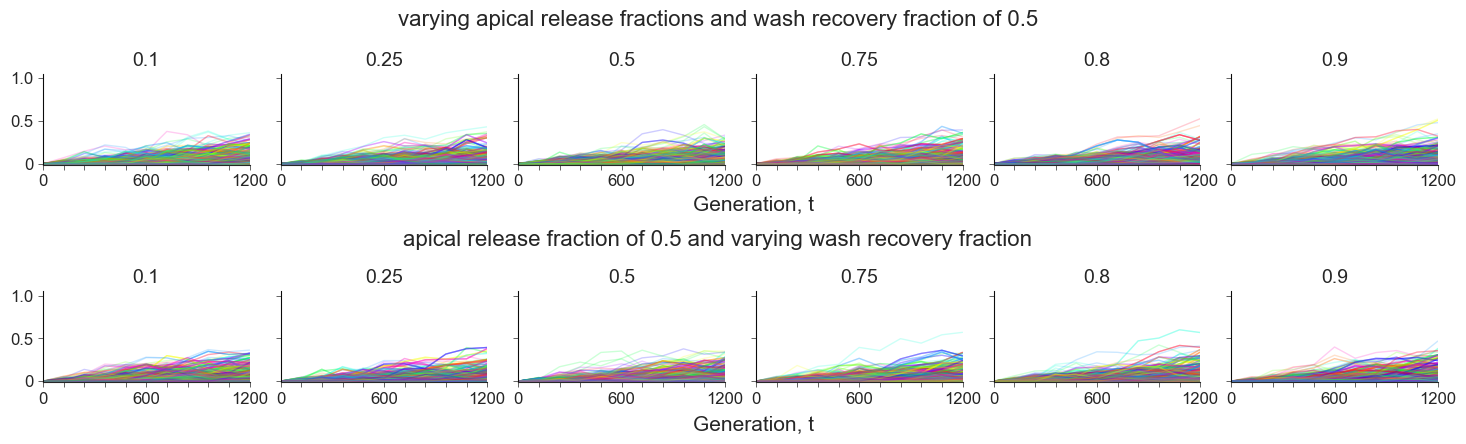

In [11]:
fig = plt.figure(figsize=(18, 4))
gs = gridspec.GridSpec(2, 1, wspace=0.25, hspace=1.4)

gsi = gridspec.GridSpecFromSubplotSpec(1,len(apical_release_fractions), wspace=0.15, hspace=0.24, subplot_spec=gs[0])

color_list = [mcolors.to_hex(cm.gist_rainbow(i /( 10-1))) for i in range(10)]

for i, apical_release_frac in enumerate(apical_release_fractions):
    ax = fig.add_subplot(gsi[i])
    
    sims= apical_simulations.loc[apical_release_frac]
    indices = sims.index.tolist()
    random.shuffle(indices)  
        
    for (wash_recovery_frac, sim, position) in indices:
        freqs = sims.loc[(wash_recovery_frac, sim, position)].values
        ax.plot(passages, freqs, lw=1, alpha=0.2, color=color_list[list(range(10)).index(sim)])

        
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, 100)
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
    ax.set_xticklabels([])
    ax.set_xticklabels([0, "", "", "", "", "600", "", "", "", "", 1200], size=12)

    if i !=0:
        ax.set_yticklabels([])
    else:
        ax.set_yticklabels([0, 0.5, 1.0], size=12)
    
    ax.set_title(f"{apical_release_frac}")
    
gsi = gridspec.GridSpecFromSubplotSpec(1,len(wash_recovery_fractions), wspace=0.15, hspace=0.23, subplot_spec=gs[1])
for i, wash_recovery_frac in enumerate(wash_recovery_fractions):
    ax = fig.add_subplot(gsi[i])
    
    sims= wash_simulations.loc[wash_recovery_frac]
    indices = sims.index.tolist()
    random.shuffle(indices)  
        
    for (apical_release_frac, sim, position) in indices:
        freqs = sims.loc[(apical_release_frac, sim, position)].values
        ax.plot(passages, freqs, lw=1, alpha=0.2, color=color_list[list(range(10)).index(sim)])
        

    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, 100)
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
    ax.set_xticklabels([0, "", "", "", "", "600", "", "", "", "", 1200], size=12)

    if i !=0:
        ax.set_yticklabels([])
    else:
        ax.set_yticklabels([0, 0.5, 1.0], size=12)
    
    ax.set_title(f"{wash_recovery_frac}")    
   

fig.text(0.5, 1, "varying apical release fractions and wash recovery fraction of 0.5", ha="center", size=16) 
fig.text(0.5, 0.45, "apical release fraction of 0.5 and varying wash recovery fraction", ha="center", size=16) 

fig.text(0.52, 0.54, "Generation, t", ha="center", size=15) 
fig.text(0.52, -0.01, "Generation, t", ha="center", size=15) 




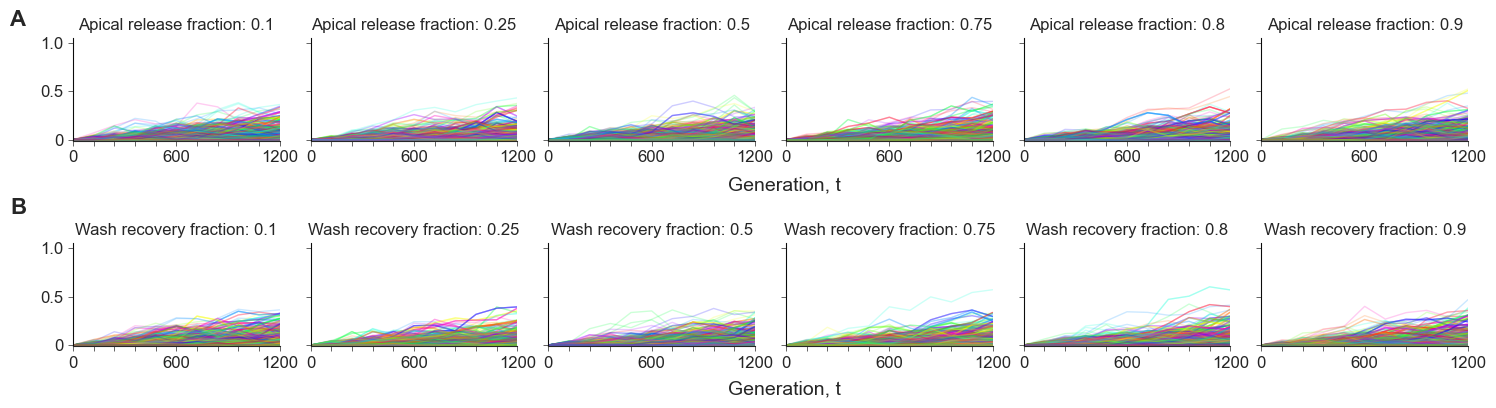

In [12]:
fig = plt.figure(figsize=(18, 4))
gs = gridspec.GridSpec(2, 1, wspace=0.25, hspace=1.)

gsi = gridspec.GridSpecFromSubplotSpec(1,len(apical_release_fractions), wspace=0.15, hspace=0.24, subplot_spec=gs[0])

color_list = [mcolors.to_hex(cm.gist_rainbow(i /( 10-1))) for i in range(10)]

for i, apical_release_frac in enumerate(apical_release_fractions):
    ax = fig.add_subplot(gsi[i])
    
    sims= apical_simulations.loc[apical_release_frac]
    indices = sims.index.tolist()
    random.shuffle(indices)  
        
    for (wash_recovery_frac, sim, position) in indices:
        freqs = sims.loc[(wash_recovery_frac, sim, position)].values
        ax.plot(passages, freqs, lw=1, alpha=0.2, color=color_list[list(range(10)).index(sim)])
        # break
        
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, 100)
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
    ax.set_xticklabels([])
    ax.set_xticklabels([0, "", "", "", "", "600", "", "", "", "", 1200], size=12)

    if i !=0:
        ax.set_yticklabels([])
    else:
        ax.set_yticklabels([0, 0.5, 1.0], size=12)
    
    ax.set_title(f"Apical release fraction: {apical_release_frac}", size=12)
    
gsi = gridspec.GridSpecFromSubplotSpec(1,len(wash_recovery_fractions), wspace=0.15, hspace=0.23, subplot_spec=gs[1])
for i, wash_recovery_frac in enumerate(wash_recovery_fractions):
    ax = fig.add_subplot(gsi[i])
    
    sims= wash_simulations.loc[wash_recovery_frac]
    indices = sims.index.tolist()
    random.shuffle(indices)  
        
    for (apical_release_frac, sim, position) in indices:
        freqs = sims.loc[(apical_release_frac, sim, position)].values
        ax.plot(passages, freqs, lw=1, alpha=0.2, color=color_list[list(range(10)).index(sim)])
        # break    

    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, 100)
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
    ax.set_xticklabels([0, "", "", "", "", "600", "", "", "", "", 1200], size=12)

    if i !=0:
        ax.set_yticklabels([])
    else:
        ax.set_yticklabels([0, 0.5, 1.0], size=12)
    
    ax.set_title(f"Wash recovery fraction: {wash_recovery_frac}", size=12)
       
   

# fig.text(0.5, 1, "varying apical release fractions and wash recovery fraction of 0.5", ha="center", size=16) 
# fig.text(0.5, 0.45, "apical release fraction of 0.5 and varying wash recovery fraction", ha="center", size=16) 

fig.text(0.09, 0.91, "A", size=16, fontweight="bold")
fig.text(0.09, 0.44, "B", size=16, fontweight="bold")


fig.text(0.52, 0.5, "Generation, t", ha="center", size=14) 
fig.text(0.52, -0.01, "Generation, t", ha="center", size=14) 


fig.savefig("../figures/figS4_simulations_sensitivity.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/figS4_simulations_sensitivity.png", dpi=300,bbox_inches='tight')   

**Figure S4 Simulated frequency trajectories with varying apical release fractions (A) and wash recovery fractions (B)**. For each simulation run we performed 10 simulations of 100 passages on a genome with 2,281 binary loci (max genome length simulated). All other parameter values were set to the default given in Supplemental Table S2, including wash recovery fraction in panel A and apical release fraction in panel B. SNV trajectories are coloured by simulation for visualization. 